# Ex2 – LMPC for minimum-time control of a unicycle (commented version)

*Annotated copy of Ugo Rosolia's notebook. **The code is exactly the same as in the original**, only comments and explanation cells were added, so it gives the same results. Put this file in the same folder as the original notebook and run it the same way.*

## What this example does, in one paragraph

A unicycle (a point "car" whose speed and heading we choose) must drive along a **curved road** (a quarter-circle-like arc of radius $R=10$, half-width 2) from a standing start to a **goal box at the end of the road, where it must arrive stopped**, in **minimum time**. We first build a slow but feasible trajectory by hand (100 steps). Then the **Learning MPC** repeats the task many times ("iterations"). After every iteration it stores the trajectory it just executed, and uses all stored data to build (i) a **safe set** of states from which it knows how to finish the task and (ii) a **cost-to-go** ($V$-function: how many steps were still needed from each stored state). Because each new trajectory can only be as good or better than the stored ones, the time to complete the task goes down iteration after iteration: here from 100 steps to about 16.

The notebook repeats this experiment for 4 different settings of how much stored data the controller uses ($l$ and $P$, explained below) and shows that using more data learns faster.

## The model (written in `utils/simulators.py` and again inside `fnc/LMPC_CT.py`)

The state is written in **road ("curvilinear") coordinates**, not in X–Y:

| symbol | Python | meaning |
|---|---|---|
| $s$ | `x[0]` | distance travelled along the road centre line |
| $e$ | `x[1]` | lateral distance from the centre line (positive = towards the inside of the curve) |
| $v$ | `x[2]` | speed |

The input is $u = (\theta, a)$: `u[0]` = heading angle of the vehicle in the fixed X–Y frame, `u[1]` = acceleration.
Since the road is a circle of radius $R$, the direction of the road at abscissa $s$ is the angle $s/R$; so $\theta - s/R$ is the heading **relative to the road**. With sampling time $\Delta t = 0.5$ s (forward Euler):

$$
\begin{aligned}
s_{t+1} &= s_t + \Delta t\, \frac{v_t \cos(\theta_t - s_t/R)}{1 - e_t/R}\\
e_{t+1} &= e_t + \Delta t\, v_t \sin(\theta_t - s_t/R)\\
v_{t+1} &= v_t + \Delta t\, a_t
\end{aligned}
$$

Constraints (set inside `LMPC_CT.solve_ftocp`): $|e|\le 2$ (stay on the road), $v \ge 0$, $|\theta|\le 2$ rad, $|a| \le 1$.

**Goal set** $\mathcal X_F$: $s$ between the end of the feasible trajectory and 0.5 m further, any $e \in[-2,2]$, and $v = 0$ (stopped).
**Cost**: 1 for every time step spent outside $\mathcal X_F$, 0 inside, so the total cost = the number of steps needed = the time to complete the task.

## Python in 2 minutes (only what you need to read this notebook)

* `#` starts a **comment**: Python ignores everything after it on that line.
* **Indentation matters.** The lines that belong to a `for`, `while`, `if`, function or class are the ones indented under it (there are no `end` or braces as in MATLAB/C).
* **Indices start at 0.** `x[0]` is the first element, `x[-1]` the last one, `x[1:4]` elements 1, 2, 3 (the end is excluded).
* `a = [1, 2, 3]` is a **list** (a container that can grow with `a.append(4)`). `np.array(...)` is a **numpy array**, the MATLAB-like matrix. For a 2-D array `A`: `A[:, 0]` is the first column, `A.T` the transpose, `A.shape` its size.
* `for k in range(5):` runs with `k = 0, 1, 2, 3, 4`. `for a, b in zip(list1, list2):` walks two lists in parallel.
* **Classes and objects.** `lmpc = LMPC_CT(...)` creates an *object* (an instance of the class `LMPC_CT`, defined in `fnc/LMPC_CT.py`). The object keeps its own data (`lmpc.SS`, `lmpc.uPred`, ...) and has its own functions, called *methods* (`lmpc.solve(...)`, `lmpc.addTrajectory(...)`). Inside the class file the object refers to itself as `self`.
* `print(...)` writes text below the cell. `plt.plot(...)` (matplotlib) works like MATLAB's `plot`.

### Cell 1 – Imports

`import` loads libraries; the order matters only because the last line needs the `sys.path` line just before it.

In [1]:
import numpy as np                     # numpy = numerical arrays and math (the "MATLAB part" of Python); used as np.xxx
from fnc.LMPC_CT import LMPC_CT        # the LMPC controller class, from file fnc/LMPC_CT.py (folder fnc next to this notebook)
from fnc.MIX_OL_CL import MIX_OL_CL    # the hand-made controller that produces the first feasible trajectory (fnc/MIX_OL_CL.py)
import pdb                             # Python debugger, NOT used here (left over from development)
import dill                            # saves/loads Python objects to files, NOT used in this notebook
import matplotlib.pyplot as plt        # plotting library; used as plt.plot, plt.xlabel, ... like MATLAB
from tempfile import TemporaryFile     # NOT used
import copy                            # NOT used
import datetime                        # NOT used
import os                              # operating-system utilities
import sys,os                          # sys gives access to sys.path = the list of folders where Python looks for files to import
sys.path.append(os.path.abspath('../../utils'))   # add the repo's utils folder (two levels up from this notebook) to that list
from simulators import *               # now Python can find utils/simulators.py; "*" imports everything in it, in particular SIMULATOR

# Minimum LMPC with time varing safe set and $V$-function
The goal of this problem is to steer the unicycle model from a starting state to a goal set in minimum time. First, we compute a feasible trajectory used to initialize the LMPC.

### Cell 2 – First feasible trajectory (iteration 0)

LMPC needs **at least one trajectory that completes the task** before it can start learning: it is the first content of the safe set. Here it is produced by a very simple open-loop rule (`fnc/MIX_OL_CL.py`):

* heading $\theta_t = s_t/R$, i.e. always point along the road, so $e$ stays at 0 (the car drives on the centre line);
* acceleration $+0.25$ for the first 3 steps (speed goes up to 0.375 m/s), then 0 (constant speed), then $-0.25$ for 3 steps near the end, so it stops.

It takes 100 steps (50 s). It is deliberately slow: the point of the example is to see LMPC improve on it.

In [2]:
# parameter initialization
radius = 10.0                          # radius R of the road centre line (m)

simulator = SIMULATOR("unicycle", radius = radius, dt = 0.5)   # object that simulates the "real" system: simulator.sim(x, u) returns the next state

N = 4                                  # MPC prediction horizon (number of predicted steps)
road_half_width = 2.0                  # the road is 4 m wide: |e| <= 2
mix_ol_cl = MIX_OL_CL(radius)          # the simple controller described above

# ====================================================================================
# Run simulation to compute feasible solution
# ====================================================================================
x0 = [0, 0, 0] # initial condition     # s = 0, e = 0, v = 0: start of the road, on the centre line, standing still
xcl_feasible = [x0]                    # closed-loop STATE history: a list of states, it starts with x0 and grows at every step
ucl_feasible =[]                       # closed-loop INPUT history: starts empty
xt           = x0
time         = 0

print("Start closed-loop simulation")
totTimeSteps = 101                     # trajectory length: 101 states, i.e. 100 inputs/steps
for time in range(totTimeSteps-1):     # time = 0, 1, ..., 99
    xt = xcl_feasible[time] # Read measurements      # current state

    mix_ol_cl.solve(xt, time, totTimeSteps) # Solve FTOCP   # here not a real optimisation: it just applies the rule above and stores it in mix_ol_cl.uPred

    # Read input and apply it to the system
    ut = mix_ol_cl.uPred               # ut = [heading, acceleration]
    ucl_feasible.append(ut)            # store the input
    xcl_feasible.append(simulator.sim(xcl_feasible[time], ut))   # simulate one step and store the new state
    time += 1                          # (useless: the for loop sets "time" itself at the next round)
print("Done closed-loop simulation")

Start closed-loop simulation
Done closed-loop simulation


### Cell 3 – Plot the road, the goal set and the feasible trajectory

The trajectory is in road coordinates $(s, e, v)$; to draw it we convert to X–Y with `simulator.from_curvilinear_to_xy`. The goal set is placed where the feasible trajectory ended: $s \in [s_{end}, s_{end}+0.5]$.

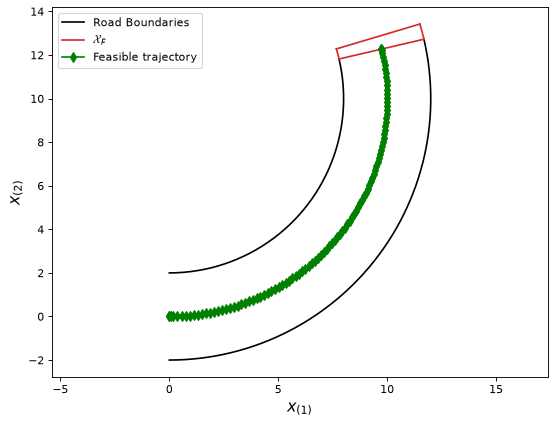

In [3]:
# Compute road edges and goal set in X-Y coordinates for plotting
s_start = 0                            # road starts at s = 0 ...
s_end = xcl_feasible[-1][0]            # ... and (for plotting) ends where the feasible trajectory ended: [-1] = last state, [0] = its s
road_boundary_left = simulator.computeRoadEdges(s_start, s_end, radius, road_half_width, signEdge=-1, disc = 0.1) # np.array(pointCircleIn)   # inner edge (circle of radius R-2), as an array of X-Y points
road_boundary_right = simulator.computeRoadEdges(s_start, s_end, radius, road_half_width, signEdge=1, disc = 0.1) # np.array(pointCircleOut)  # outer edge (radius R+2)

s_finish_line_start = xcl_feasible[-1][0]          # goal set starts at the final s of the feasible trajectory
s_finish_line_end = s_finish_line_start + 0.5      # and is 0.5 m long
goal_region_left = simulator.computeRoadEdges(s_finish_line_start, s_finish_line_end, radius, road_half_width, signEdge=-1, disc = 0.1) # np.array(pointCircleIn)
goal_region_right = simulator.computeRoadEdges(s_finish_line_start, s_finish_line_end, radius, road_half_width, signEdge=1, disc = 0.1) # np.array(pointCircleOut)

#Plot closed-loop trajectory
plt.figure(figsize=(8, 6), dpi=80)     # new figure (size in inches)
plt.plot(road_boundary_left[:,0], road_boundary_left[:,1], '-k', label='Road Boundaries')   # [:,0] = all X values, [:,1] = all Y values; '-k' = black line
plt.plot(road_boundary_right[:,0], road_boundary_right[:,1], '-k')

# the goal set is drawn as a red box: its two long sides ...
plt.plot(goal_region_left[:,0], goal_region_left[:,1], '-', color='C3', label='$\mathcal{X}_F$')   # text between $...$ is LaTeX
plt.plot(goal_region_right[:,0], goal_region_right[:,1], '-', color='C3')
# ... and its two short sides (segments joining first points and last points)
plt.plot([goal_region_right[0,0], goal_region_left[0,0]], [goal_region_right[0,1], goal_region_left[0,1]], '-', color='C3')
plt.plot([goal_region_right[-1,0], goal_region_left[-1,0]], [goal_region_right[-1,1], goal_region_left[-1,1]], '-', color='C3')

# Convert from curvilinear to XY
xcl_feasible_xy = simulator.from_curvilinear_to_xy(xcl_feasible)       # list of [X, Y] points
plt.plot(np.array(xcl_feasible_xy)[:,0], np.array(xcl_feasible_xy)[:,1], '-dg', label='Feasible trajectory')   # '-dg' = green line with diamond markers

plt.xlabel('$x_{(1)}$', fontsize=14)
plt.ylabel('$x_{(2)}$', fontsize=14)
plt.legend()
plt.axis('equal');                     # same scale on both axes, so the circle looks round; the final ";" just hides a printed message

**Run LMPC for different parameters**

In the implementation below we used a subset of stated to design the LMPC. In particular, we have that:
- $P$ represents the number of states used to build the convex time varying safe set
- $l$ represents the number of previous iterations used to construct the convex time varying safe set

### Cell 4 – The learning loop (this is the slow cell: several minutes)

**How the controller works at each time step** (details in `fnc/LMPC_CT_commented.py`):

1. **Local safe set.** Take the stored trajectories of the last $l$ iterations. From each of them take $P$ consecutive stored states, chosen around "where that trajectory was about $N$ steps after the current time" (the window moves forward by one at every time step, which is why it is called *time-varying*). Each stored state $x_k$ comes with its cost-to-go $V_k$ = number of steps that trajectory still needed to reach the goal from $x_k$.
2. **Convex safe set.** The terminal predicted state must be a **convex combination** of these stored states: $x_N = \sum_k \lambda_k x_k$, $\lambda_k \ge 0$, $\sum_k\lambda_k = 1$. The terminal cost is the same combination of costs: $\sum_k \lambda_k V_k$. (Since the system is nonlinear this is the "convex" relaxation used in the chapter.)
3. **Optimisation.** Find the $N$ inputs that minimise (steps over the horizon) + (terminal cost), subject to dynamics and constraints. It is a nonlinear program, solved with IPOPT via CasADi.
4. **Receding horizon.** Apply only the first input, measure the new state, repeat until the car is in the goal set.

When the task is completed, the whole new trajectory is added to the stored data and a new iteration starts from $x_0$.

The outer loop repeats everything for 4 settings, from little data to a lot of data:

| setting | $l$ (past iterations used) | $P$ (points per iteration) |
|---|---|---|
| 1 | 1 | 15 |
| 2 | 3 | 20 |
| 3 | 4 | 50 |
| 4 | 10 | 200 |

For each setting a fresh controller is created and run for 10 iterations. The text printed below the cell gives the time to complete the task at each iteration.

In [4]:
%%time
P_list = [15, 20, 50, 200]             # values of P for the 4 settings
l_list = [1, 3, 4, 10]                 # values of l for the 4 settings
itMax = 10 # Number or iteration to perform per LMPC settings

xcl_pl = []                            # will collect, for each setting, all the stored trajectories (used later for the plots)
for l,P in zip(l_list, P_list):        # (l,P) = (1,15), then (3,20), then (4,50), then (10,200)
    print("Running LMPC for (l,P) = (", l,", ",P,")")
    # Initialize LMPC
    lmpc = LMPC_CT(N, simulator.dt, road_half_width,  l = l, P = P, verbose = False)   # new controller, with empty memory

    # Construct terminal goal set
    # Xf is a 3x2 matrix: column 0 = lower bounds, column 1 = upper bounds of (s, e, v)
    #   s in [s_finish_line_start, s_finish_line_end], e in [-2, 2], v in [0, 0] (i.e. stopped)
    Xf = np.array([[s_finish_line_start, -road_half_width, 0.0],[s_finish_line_end, road_half_width, 0.0]]).T
    lmpc.set_xf(Xf)                    # tell the controller the goal box
    # Build the 4 corners of the goal box (3x4 matrix, one corner per column). They are added to the
    # safe set with cost-to-go 0, so the controller can also aim directly for any point of the goal box.
    Xf_vertices = np.concatenate((Xf,Xf), axis = 1 )      # 4 columns: (lo,lo), (hi,hi), (lo,lo), (hi,hi)
    Xf_vertices[1,2] = road_half_width                     # change e in column 2 -> corner (s_lo, +2, 0)
    Xf_vertices[1,3] = -road_half_width                    # change e in column 3 -> corner (s_hi, -2, 0)
    lmpc.Xf_vertices = Xf_vertices

    # Add feasible trajectory to the safe set
    lmpc.addTrajectory(xcl_feasible, ucl_feasible)        # iteration 0 = the slow hand-made trajectory

    itCounter = 0
    while itCounter < itMax: # Iteration loop             # repeat the task itMax = 10 times
        time = 0
        xcl = [x0]                     # every iteration starts again from the same initial state
        ucl = []
        while (lmpc.checkTaskCompletion(xcl[-1]) == False): # Time loop   # continue until the last state is inside the goal box
            # read measurement
            xt = xcl[time]

            # Solve LMPC
            lmpc.solve(xt, verbose = 1)                    # solves the optimisation; result in lmpc.uPred (2 x N matrix of predicted inputs)

            # Apply input and store closed-loop data
            ut = lmpc.uPred[:,0]                           # first column = first input only (receding horizon)
            ucl.append(ut)
            xcl.append(simulator.sim(xcl[time], ut))       # the "real" system moves one step

            # increment time counter
            time += 1

        # iteration completed. Add trajectory to the safe set
        lmpc.addTrajectory(xcl, ucl)   # this is the "learning": the new, faster trajectory enlarges/improves the stored data

        # Print and store results
        print("Completed Iteration: ", itCounter+1, ". Time to complete the task: ", len(xcl)-1)   # number of steps = number of states - 1

        # Increment iteration counter
        itCounter += 1

    xcl_pl.append(lmpc.SS)             # lmpc.SS = list of all stored trajectories (iteration 0 ... 10), each a 3 x (T+1) array

Running LMPC for (l,P) = ( 1 ,  15 )

******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************



CasADi - 2026-11-02 22:28:06 WARNING("KeyboardInterruptException") [.../casadi/interfaces/ipopt/ipopt_nlp.cpp:132]


SystemError: <built-in function Function_call> returned a result with an exception set

### Cell 5 – Plot the results

* **First figure** (`NonlinearLMPC_Task.pdf`): road, goal set, the feasible trajectory (black) and, for each setting, the trajectory of the **last** iteration. The learned trajectories cut to the inside of the curve (shorter path) and are much faster, with fewer, more widely spaced points.
* **Second figure** (`NonlinearLMPC_Cost.pdf`): time to complete the task versus iteration $j$, one curve per setting. All settings converge to the same value (about 16–17 steps), but the ones using more data ($l$, $P$ larger) get there in 2–3 iterations instead of 6–7.

Two small things to know when you read the figures:
* in the legends, `i=` is actually $l$ (the number of past iterations);
* the cost plot uses the number of stored **states**, i.e. steps + 1. So iteration 0 shows 101, whereas the printout above reports 100 steps.

Both figures are also saved as PDF files in this folder, overwriting Ugo's: compare with the copies on GitHub to check your run.

In [ ]:
plt.figure(figsize=(10, 6), dpi=80)
# Plot road boundaries and goal set (same as cell 3)
plt.plot(road_boundary_left[:,0], road_boundary_left[:,1], '-k', label='Road Boundaries')
plt.plot(road_boundary_right[:,0], road_boundary_right[:,1], '-k')
plt.plot(goal_region_left[:,0], goal_region_left[:,1], '-', color='C3', label='$\mathcal{X}_F$')
plt.plot(goal_region_right[:,0], goal_region_right[:,1], '-', color='C3')
plt.plot([goal_region_right[0,0], goal_region_left[0,0]], [goal_region_right[0,1], goal_region_left[0,1]], '-', color='C3')
plt.plot([goal_region_right[-1,0], goal_region_left[-1,0]], [goal_region_right[-1,1], goal_region_left[-1,1]], '-', color='C3')

# Convert from curvilinear to XY
xcl_feasible_xy = simulator.from_curvilinear_to_xy(xcl_feasible)
plt.plot(np.array(xcl_feasible_xy)[:,0], np.array(xcl_feasible_xy)[:,1], '-ok', label='Feasible trajectory')


for i in range(len(xcl_pl)):           # i = 0..3, one per (l,P) setting
    # xcl_pl[i][-1] = last stored trajectory (3 x T array) of setting i; .T.tolist() turns it into a list of states for the conversion
    xcl_xy = simulator.from_curvilinear_to_xy(xcl_pl[i][-1].T.tolist())
    plt.plot(np.array(xcl_xy)[:,0], np.array(xcl_xy)[:,1], '-o', label="LMPC closed-loop for P = "+str(P_list[i])+", i="+str(l_list[i]))   # str() turns a number into text


plt.xlabel('$x_{1}$', fontsize=14)
plt.ylabel('$x_{2}$', fontsize=14)
plt.legend(fontsize=12)
plt.axis('equal');
plt.savefig('NonlinearLMPC_Task.pdf')  # save the figure in this folder

plt.figure(figsize=(10, 6), dpi=80)
for i in range(len(xcl_pl)):           # one curve per setting
    task_completion = []
    for xcl_at_it in xcl_pl[i]:        # loop over the stored trajectories: iteration 0, 1, ..., 10
        task_completion.append(xcl_at_it.shape[1])   # shape[1] = number of columns = number of states in that trajectory
    plt.plot(task_completion, '-o', label="LMPC closed-loop for P = "+str(P_list[i])+", i="+str(l_list[i]))

plt.legend(fontsize=14)
plt.xlabel('$\mathrm{Iteration~}j$', fontsize=14)
plt.ylabel('$\mathrm{Time~steps~to~complete~the~task~}T^j$', fontsize=14)
plt.savefig('NonlinearLMPC_Cost.pdf')

## Things to try (one at a time, then *Kernel → Restart Kernel and Run All Cells*)

* **Fewer settings, faster runs.** For quick tests set `P_list = [50]` and `l_list = [4]` in cell 4: one setting instead of four.
* **Horizon.** Change `N = 4` in cell 2 (e.g. 2 or 6) and see how the final time and the learning speed change. A longer horizon makes each optimisation slower.
* **Road width.** Change `road_half_width`: a wider road allows a shorter path inside the curve.
* **Slower first trajectory.** Change `totTimeSteps` in cell 2. LMPC should converge to roughly the same optimum whatever the initial feasible trajectory.
* **Look inside.** After cell 4 has run, create a new cell and type, e.g., `lmpc.SS[-1]` (last stored trajectory) or `lmpc.Vfun[-1]` (its cost-to-go) and press Shift+Enter to see the numbers.

Why it is slow: in `LMPC_CT.solve` the nonlinear program is rebuilt from scratch (CasADi + IPOPT) at **every** time step, and `solve_ftocp` solves it up to $N$ times, once for each possible number of final predicted states forced into the goal set (needed because the stage cost 0/1 is not smooth).